### ELO328 - Procesamiento Digital de Imágenes
# Clase 4: Detección de bordes
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Filtros digitales

Los filtros se pueden clasificar en:

- Filtros en el dominio del espacio: trabajan directamente sobre los píxeles de la imagen.
    - [x] Suavizado: difuminado (blurring) o eliminación de ruido.
        - [x] Filtros lineales: media, gaussiano.
        - [x] Filros no lineales: máximo, mínimo, mediana.
    - **Realce: detección de lados o bordes.**
- Filtros en el dominio de la frecuencia: las operaciones se llevan a cabo en la transformada de Fourier de la imagen. Pueden eliminar altas o bajas frecuencias de la imagen, lo que se traduce en suavizar la imagen, o bien, realzar o detectar bordes.

# Bordes

Los bordes de una imagen se definen como variaciones locales en la intensidad de la imagen.

Por ejemplo, en una imagen binaria el paso de un nivel oscuro a uno claro, o viceversa, definen un borde.

<div align="center">
    <img src="img/binaryborder.png" alt="" width="60%" align="center" />
</div>

# Filtros espaciales de realce

- Permiten realzar los cambios en los valores de grises y atenuar las áreas donde existen valores constantes. 
- Útiles para detectar los bordes de una imagen.
- La idea es el cálculo de un operador local de derivación, ya que un píxel pertenece a un borde si se produce un cambio brusco en los niveles de grises con sus vecinos.
- Problema colateral: realzan ruido.

# Derivadas de una función digital

- La primera derivada es cero en zonas de intensidad constante y distinta de cero en zonas de variaciones (escalones o rampas).
- La segunda derivada debe ser cero en zonas de intensidad constante y a lo largo de rampas con pendiente constante y debe ser distinta de cero en escalones y en comienzo y fin de rampas.

<div align="center">
    <img src="img/derivate.jpg" alt="" width="60%" align="center" />
</div>

Una definición básica de la derivada de primer orden de una función $f(x)$ en una dimensión  es:

$$ \frac{\partial f}{\partial x} = f(x+1) - f(x) $$

En tanto, la derivada de segundo orden de $f(x)$ es :

$$ \frac{\partial^2 f}{\partial x^2} = f(x+1) + f(x-1) - 2f(x) $$

En general, la segunda derivada será más sensible que la primera ante cambios bruscos en la imagen, por lo que también detectará más sutilmente el ruido.

# El Laplaciano

- Utiliza la derivada de segundo orden para construir un filtro basado en un Kernel que hace uso de esta formulación.

- La ecuación anterior definía la derivada de segundo orden de una función en una dimensión. Para una función en dos dimensiones $f(x,y)$, el Laplaciano se define como:

$$ \nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2} $$

- De las ecuaciones anteriores se deduce que el laplaciano discreto de dos variables es:

$$ \nabla^2 f = f(x+1,y) + f(x-1,y) + f(x,y+1) + f(x,y-1) - 4f(x,y)  $$


# El Kernel Laplaciano
Para representar la ecuación anterior

$$ \nabla^2 f = f(x+1,y) + f(x-1,y) + f(x,y+1) + f(x,y-1) - 4f(x,y),  $$

se utiliza la siguiente máscara:

<div align="center">
    <img src="img/laplaciano.jpg" alt="" width="20%" align="center" />
</div>

# Ejemplo en Python

In [1]:
from skimage.io import imread
from skimage import filters
from skimage import feature
from scipy.signal import convolve2d
from scipy.ndimage import median_filter
from matplotlib import pyplot as plt
from skimage.color import rgb2gray
import numpy as np

In [2]:
flor = imread("img/flor.jpg")
lena = imread("img/lena.jpg")

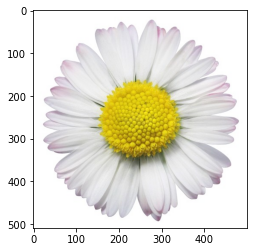

In [3]:
plt.imshow(flor)
plt.show()

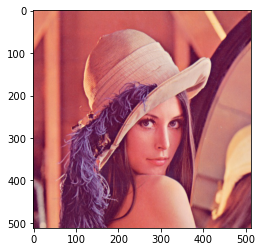

In [4]:
plt.imshow(lena)
plt.show()

In [5]:
def laplacian_kernel():
    mask = np.array([[0, 1, 0],
                    [1, -4, 1],
                    [0, 1, 0]])
    return mask

In [6]:
def laplaciano(imagen, gray=False):
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121) 
    ax2 = fig.add_subplot(122)     
    if gray:
        imagen = rgb2gray(imagen)
        ax1.imshow(imagen, cmap='binary') 
        ax1.set_title("Imagen Original en escala de grises")
        out = abs(convolve2d(imagen, laplacian_kernel(), mode="same", boundary="fill"))
        ax2.set_title("Filtro Laplaciano")
        ax2.imshow(out, cmap='binary')
    else:
        ax1.imshow(imagen) 
        ax1.set_title("Imagen Original en formato RGB")
        ims = []
        for d in range(3):
            g = convolve2d(imagen[:,:,d], laplacian_kernel(), mode="same", boundary="fill")
            ims.append(g)        
        im_conv = np.stack(ims, axis=2).astype("uint8")
        ax2.set_title("Filtro Laplaciano")
        ax2.imshow(im_conv)    
    plt.show()

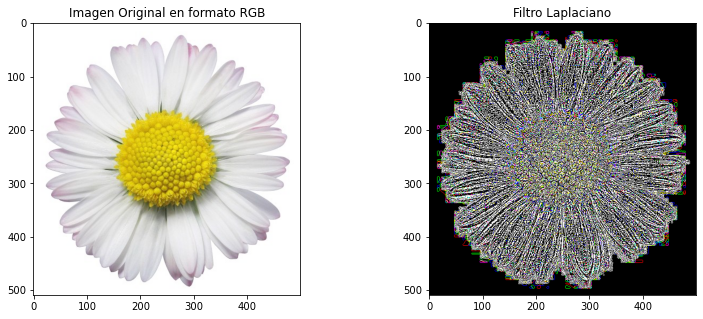

In [7]:
laplaciano(flor)

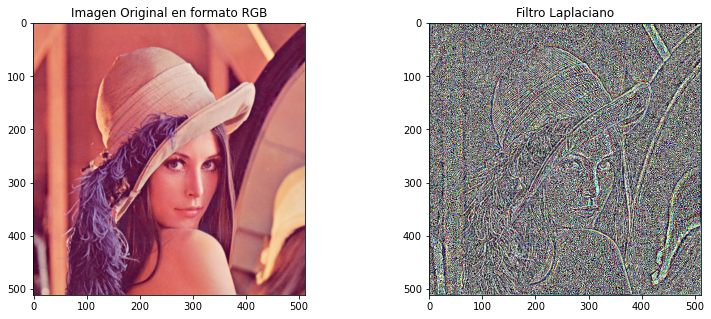

In [8]:
laplaciano(lena)

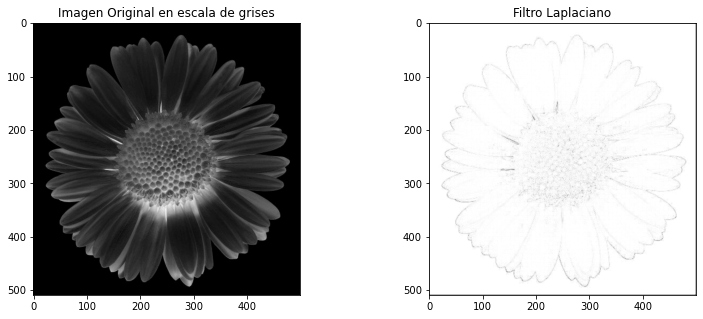

In [9]:
# Aplicar Laplaciano para imagen en escala de grises
laplaciano(flor, gray=True)

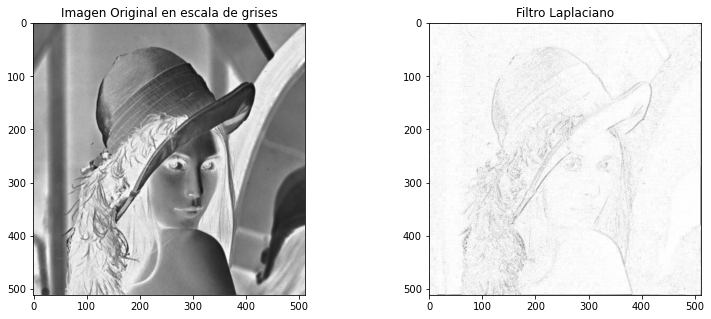

In [10]:
# Aplicar Laplaciano para imagen en escala de grises
laplaciano(lena, gray=True)

# El gradiente digital

Las primeras derivadas en procesamiento de imágenes están implementadas usando la magnitud del gradiente.

El *gradiente* de una imagen $f$ en las coordenadas $(x,y)$, se define como el siguiente vector columna de dos dimensiones:

$$ \nabla f =  \begin{bmatrix}
g_x  \\
g_y  
\end{bmatrix} = \begin{bmatrix}
\frac{\partial f}{\partial x}  \\
\frac{\partial f}{\partial y}  
\end{bmatrix} $$ 

Este vector tiene la importante propiedad geométrica que apunta en la dirección de la mayor tasa de cambio de $f$ en el punto $(x, y)$.

Una vez calculado el vector gradiente, la magnitud del gradiente queda definida por:

$$ M(x,y) =  \|\nabla f \| = \left(\left(\frac{\partial f}{\partial x}\right)^2 + \left(\frac{\partial f}{\partial y}\right)^2\right)^{1/2} = \sqrt{g_x^2+g_y^2} $$

Sin embargo, se suele calcular la suma del valor absoluto de sus coordenadas en lugar del módulo (por ser menos costoso).

$$ M(x,y) \approx \left|\frac{\partial f}{\partial x}\right| + \left|\frac{\partial f}{\partial y}\right| = |g_x|+|g_y| $$

Los valores grandes corresponden a píxeles del borde o a ruido. En tanto, la dirección del gradiente está dada por:

$$ \theta = \arctan\left(\frac{g_x}{g_y}\right) $$

Como en el caso del Laplaciano, ahora definiremos aproximaciones discretas a las ecuaciones anteriores, y a partir de ellas formularemos los Kernel apropiados.

Por conveniencia y simpleza denotaremos las intensidades de los píxeles usando los valores de la siguiente cuadrícula:

<div align="center">
    <img src="img/Zs.png" alt="" width="25%" align="center" />
</div>

Por ejemplo, el valor del punto central, $z_5$, denota el valor de $f(x, y)$; $z_1$ denota el valor de $f(x−1,y−1)$; y así.

<div align="center">
    <img src="img/Zs.png" alt="" width="20%" align="center" />
</div>

Entonces, las primeras derivadas:

$$ \begin{align} \frac{\partial f}{\partial x} &= g_x = f(x+1,y) - f(x-1,y) = z_8 - z_2 =& \begin{bmatrix}
-1 \\
0 \\
1
\end{bmatrix}  \\
\frac{\partial f}{\partial y} &= g_y = f(x,y+1) - f(x,y-1) = z_6 - z_4 =& \begin{bmatrix}
-1 & 0 & 1
\end{bmatrix}\end{align} $$



# Filtro gaussiano

Finalmente, si se aplica un filtro gaussiano para reducir el ruido, se obtiene:

$$
\begin{align}
\underbrace{\begin{bmatrix}
-1 \\
0 \\
1
\end{bmatrix}}_{g_x}
\otimes 
&
\underbrace{\begin{bmatrix}
1 & 2 & 1
\end{bmatrix}}_{\text{1D Gaussian Filter}}
\Longrightarrow
\underbrace{\begin{bmatrix}
-1 & -2 & -1 \\
0 & 0 & 0 \\
+1 & +2 & +1 
\end{bmatrix}}_{\text{Horizontal Sobel Filter}} \\
\underbrace{\begin{bmatrix}
1 \\
2 \\
1 
\end{bmatrix}}_{\text{1D Gaussian Filter}}
\otimes 
&
\underbrace{\begin{bmatrix}
-1 & 0 & 1
\end{bmatrix}}_{g_y}
\Longrightarrow
\underbrace{\begin{bmatrix}
-1 & 0 & +1 \\
-2 & 0 & +2 \\
-1 & 0 & +1 
\end{bmatrix}}_{\text{Vertical Sobel Filter}}
\end{align}
$$

# Operador Sobel

La operación anterior, nos entrega las máscaras de Sobel:

<div align="center">
    <img src="img/sobel.jpg" alt="" width="40%" align="center" />
</div>

Observemos que en las máscaras de Sobel, tienen más peso los píxeles situados en posición vertical y horizontal respecto a la diagonal.

In [11]:
# Horizontal Sobel Filter
def h_sobel():
    mask = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]])
    return mask

# Vertical Sobel Filter
def v_sobel():
    mask = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
    return mask

In [12]:
def plot_gradients(imagen, gray=False):
    if gray:
        gx = abs(convolve2d(rgb2gray(imagen), h_sobel(), mode="same", boundary="fill"))
        gy = abs(convolve2d(rgb2gray(imagen), v_sobel(), mode="same", boundary="fill"))
    else:
        h = []
        v = []
        for d in range(3):
            h_ = convolve2d(imagen[:,:,d], h_sobel(), mode="same", boundary="fill")
            h.append(h_)        
            v_ = convolve2d(imagen[:,:,d], v_sobel(), mode="same", boundary="fill")
            v.append(v_)        
        gx = np.stack(h, axis=2).astype("uint8")
        gy = np.stack(v, axis=2).astype("uint8")
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121)        
    ax1.imshow(gx, cmap='binary')  
    ax1.set_title("Gx")
    ax2 = fig.add_subplot(122)   
    ax2.imshow(gy, cmap='binary')    
    ax2.set_title("Gy")
    plt.show()

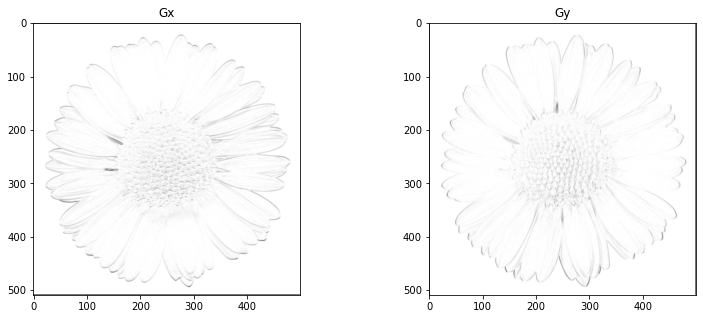

In [13]:
plot_gradients(flor, gray=True)

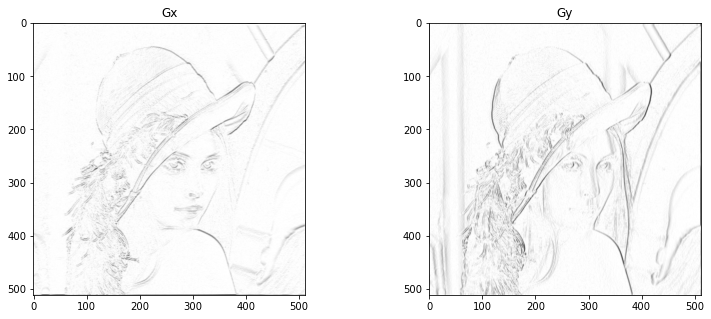

In [14]:
plot_gradients(lena, gray=True)

In [15]:
def sobel(imagen, gray=False):  
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121) 
    ax2 = fig.add_subplot(122)    
    if gray:
        imagen = rgb2gray(imagen)
        ax1.imshow(imagen, cmap='binary') 
        ax1.set_title("Imagen Original en escala de grises")
        sx = abs(convolve2d(imagen, h_sobel(), mode="same", boundary="fill"))
        sy = abs(convolve2d(imagen, v_sobel(), mode="same", boundary="fill"))
        out = np.sqrt(sx*sx + sy*sy)
        ax2.set_title("Filtro de Sobel")
        ax2.imshow(out, cmap='binary')
    else:
        ax1.imshow(imagen) 
        ax1.set_title("Imagen Original")
        ims = []
        for d in range(3):
            sx = convolve2d(imagen[:,:,d], h_sobel(), mode="same", boundary="fill")
            sy = convolve2d(imagen[:,:,d], v_sobel(), mode="same", boundary="fill")
            ims.append(np.sqrt(sx*sx + sy*sy))        
        im_conv = np.stack(ims, axis=2).astype("uint8")
        ax2.set_title("Filtro de Sobel")
        ax2.imshow(im_conv)    
    plt.show()

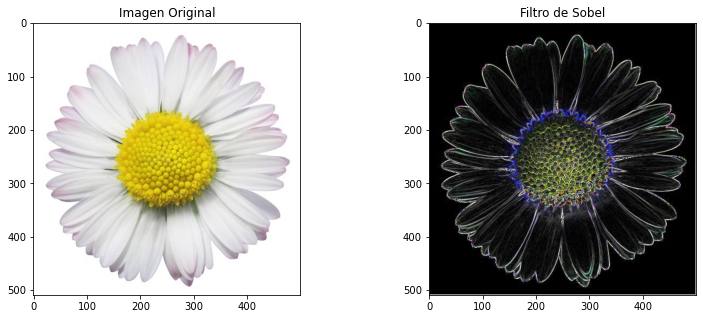

In [16]:
sobel(flor)

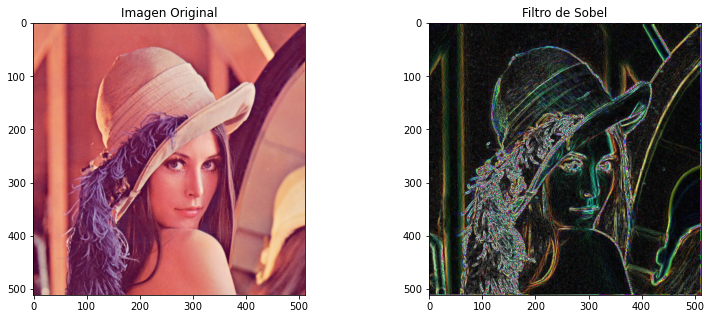

In [17]:
sobel(lena)

In [18]:
def filtro_mediana(imagen, tamaño=1):
    ims = []
    for d in range(3):
        g = median_filter(imagen[:,:,d], size=(tamaño,tamaño))
        ims.append(g)
    im_conv = np.stack(ims, axis=2).astype("uint8")
    return im_conv

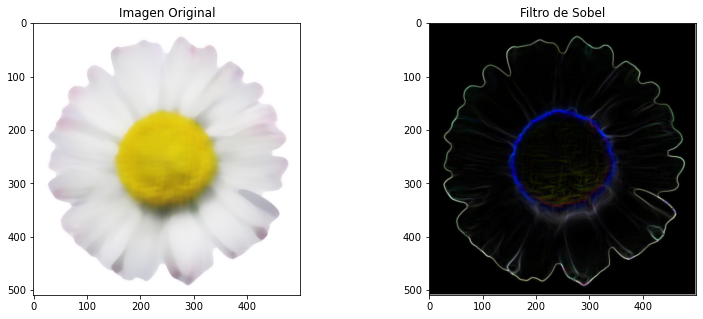

In [19]:
sobel(filtro_mediana(flor, 20))

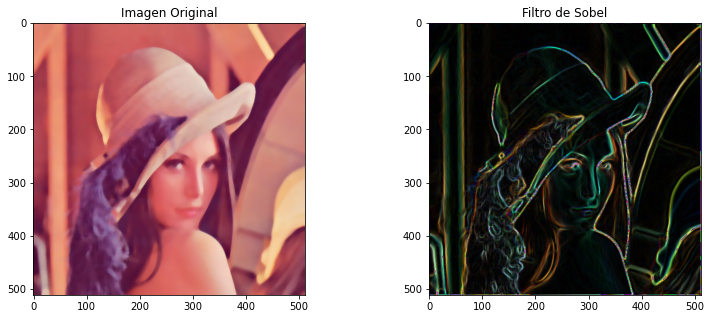

In [20]:
sobel(filtro_mediana(lena, 10))

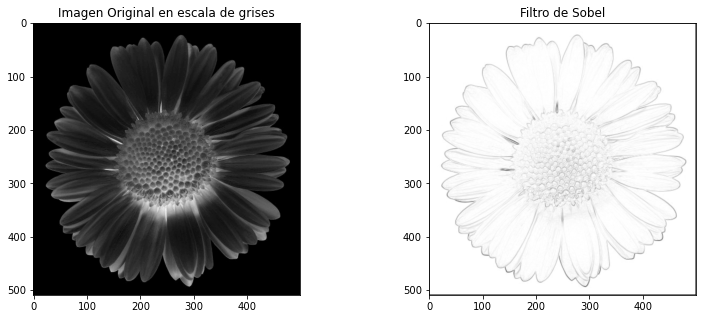

In [21]:
# Aplicar Sobel para imagen en escala de grises
sobel(flor, gray=True)

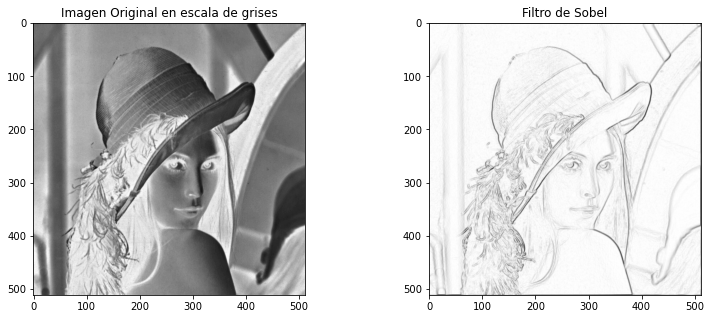

In [22]:
# Aplicar Sobel para imagen en escala de grises
sobel(lena, gray=True)

# Detector de Bordes Canny

- Es el detector de bordes más potente que existe actualmente.
- Generalmente, toma como punto de partida el resultado entregado por Sobel y le aplica el principio de "Non-Maximum Suppression" para adelgazar los bordes.
- Finalmente, realiza un proceso conocido como "Umbral de Histéresis" para eliminar falsos bordes o bordes dobles, al mismo tiempo que permite un resultado conexo.

# Detector de Bordes Canny

## Reducción de ruido

- Suavizar la imagen para filtrar el ruido y detalles irrelevantes.
- Canny utiliza el Filtro Gaussiano.

# Detector de Bordes Canny

## Aplicar método de Detección de Bordes

- Esta etapa busca una primera aproximación a los bordes.
- Los métodos de detección de bordes presentados previamente obtienen una buena primera aproximación a los bordes en la imagen (bordes gruesos).
- En general, se utiliza el método de Sobel, pero es posible utilizar cualquier método que permita obtener un estimador de la dirección.

# Detector de Bordes Canny

## Non-Maximum Suppression

- Técnica para adelgazar los bordes obtenidos previamente (eliminar bordes redundantes o duplicados).
- Para cada píxel busca si es un máximo local en su vecindario en la dirección del gradiente. Si no cumple, se elimina (se asigna valor 0).

# Detector de Bordes Canny

## Non-Maximum Suppression

### Clasificar las direcciones de borde

Para cada píxel, el vecindario está compuesto por píxeles localizados en direcciones verticales, horizontales y en diagonales (0°, 45°, 90° y 135°). Por lo tanto, se necesita discretizar la dirección del gradiente en algunos intervalos.

<div align="center">
    <img src="img/direction.png" alt="" width="30%" align="left" />
    <img src="img/mapping.png" alt="" width="30%" align="center" />
</div>

# Detector de Bordes Canny

## Non-Maximum Suppression (continuación)

- A continuación, se compara el valor del píxel en el centro de la ventana con respecto a los dos vecinos en la dirección del gradiente.
- Si la intensidad del píxel (magnitud del gradiente) es máximo local se mantiene como borde, en caso contrario se elimina.
- En general, se asume que el blanco representa el valor más alto (255) y el negro representa el valor más bajo (0), pero podría ser al revés.

# Detector de Bordes Canny

## Non-Maximum Suppression

### Ejemplo 1

- Píxel con dirección de gradiente 90° (vecinos en norte y sur).  
- Magnitud del gradiente no es mayor que ambos vecinos (sur es mayor). 
- Por lo tanto, píxel se elimina porque no es borde.

<div align="center">
    <img src="img/90.png" alt="" width="20%" align="left" />
    <img src="img/90-2.png" alt="" width="20%" align="left" />
</div>

# Detector de Bordes Canny

## Non-Maximum Suppression

### Ejemplo  2

- Píxel con dirección de gradiente 0° (vecinos en este y oeste).  
- Magnitud del gradiente es mayor que ambos vecinos.
- Por lo tanto, píxel se mantiene porque es borde.

<div align="center">
    <img src="img/0.png" alt="" width="20%" align="left" />
    <img src="img/0.png" alt="" width="20%" align="left" />
</div>

# Detector de Bordes Canny

## Non-Maximum Suppression

### Ejemplo con bordes negros y fondo blanco

<div align="center">
    <img src="img/non-max-sup.jpg" alt="" width="90%" align="center" />
</div>

# Detector de Bordes Canny

## Umbral de histéresis

- Consiste en determinar un umbral por el cual se decide si un píxel forma parte del fondo o forma parte de un objeto.
- Histéresis usa 2 umbrales, uno alto Th (exigente) y uno bajo Tl.
    - Si el valor del píxel es mayor que el umbral máximo, el píxel se considera parte del borde.
    - Un píxel se considera que no es borde si su valor es menor que el umbral mínimo,
    - Si está entre el máximo y el mínimo, será parte del borde si está conectado con un píxel que forma ya parte del borde.

# Detector de Bordes Canny

## Umbral de histéresis

### Ejemplo

<div align="center">
    <img src="img/histeresis.jpg" alt="" width="40%" align="center" />
</div>

In [23]:
def canny(imagen):
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121)        
    ax2 = fig.add_subplot(122)       
    imagen = rgb2gray(imagen)
    ax1.imshow(imagen, cmap='binary') 
    ax1.set_title("Imagen Original en escala de grises")
    edge = feature.canny(imagen)
    ax2.imshow(edge, cmap='binary')
    ax2.set_title("Filtro de Canny")
    plt.show()

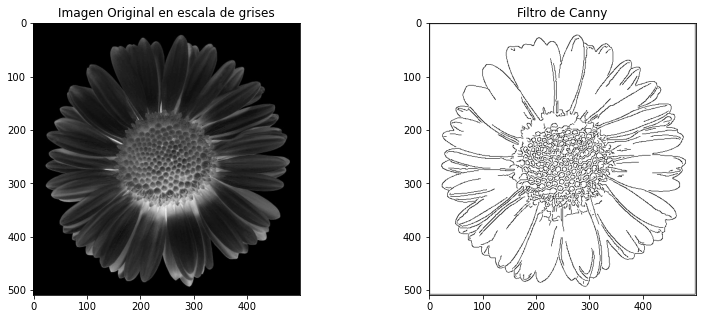

In [24]:
canny(flor)

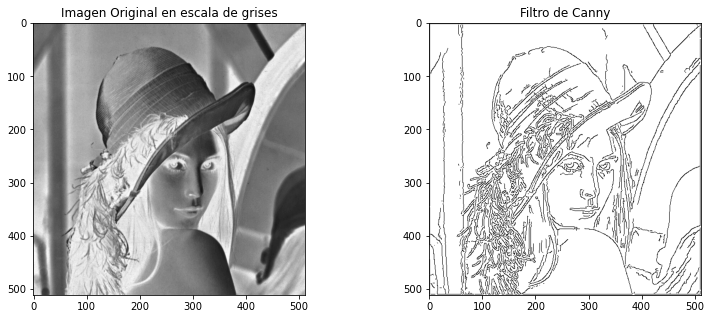

In [25]:
canny(lena)